# Prepoznavanje zdravstvenog stanja pčela sa fotografije
### KORAK 5: Da li model gleda grinju? Test van skupa i izbor modela

BeeImage model je imao 97% i nije gledao bolest. Zato se za nove modele ne prihvata samo tačnost —
proverava se **na šta model gleda** i kako radi **na slikama drugačijeg porekla**.

## 1. Uvoz biblioteka

In [1]:
import sys, os, json, ast, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw

# src.evaluate pri importu prebacuje matplotlib u "Agg" (bez prikaza) — zato se
# učitava ovde, pa se prikaz u notebook-u vraća sa %matplotlib inline
import src.evaluate, src.model_checks
%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 60)

GRAFICI = ROOT / "grafici"; GRAFICI.mkdir(exist_ok=True)
RUNS = ROOT / "runs"

# Iste boje u svim graficima
BOJA_KLASE = {"zdrava": "#2ecc71", "varoa": "#e74c3c"}
BOJA_MODELA = {"MobileNetV3-Large": "#3498db", "ResNet50": "#9b59b6", "EfficientNetB0": "#f39c12"}
MODELI = ["MobileNetV3-Large", "ResNet50", "EfficientNetB0"]
RUN_ZA = {"MobileNetV3-Large": "varroa_mobilenet_v3_large", "ResNet50": "varroa_resnet50",
          "EfficientNetB0": "varroa_efficientnet_b0"}

def sacuvaj(ime):
    """Čuva trenutni grafik u grafici/<ime>.png (isti grafici idu u prezentaciju)."""
    plt.savefig(GRAFICI / f"{ime}.png", dpi=150, bbox_inches="tight")

def oznaci_stubice(ax, fmt="{:.3f}", rot=0, size=9):
    for p in ax.patches:
        h = p.get_height()
        if np.isfinite(h) and h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h), ha="center",
                        va="bottom", fontsize=size, rotation=rot, xytext=(0, 2), textcoords="offset points")

print("Biblioteke uspešno učitane. Koren projekta:", ROOT)

checks = {m: json.loads((RUNS / RUN_ZA[m] / "checks.json").read_text()) for m in MODELI}

Biblioteke uspešno učitane. Koren projekta: /Users/medzidjasarovic/Kosnica_IS/KosnicaML


## 2. Provera 1 — brisanje grinje (uzročni test)

Na svakoj zaraženoj test pčeli koju je model prepoznao, grinja se **prekrije bojom okoline**.
Ako model gleda grinju → procena prelazi u „zdrava“.
**Kontrola:** isto toliko mesta se prekrije na **drugom delu pčele** → procena treba da ostane „varoa“.

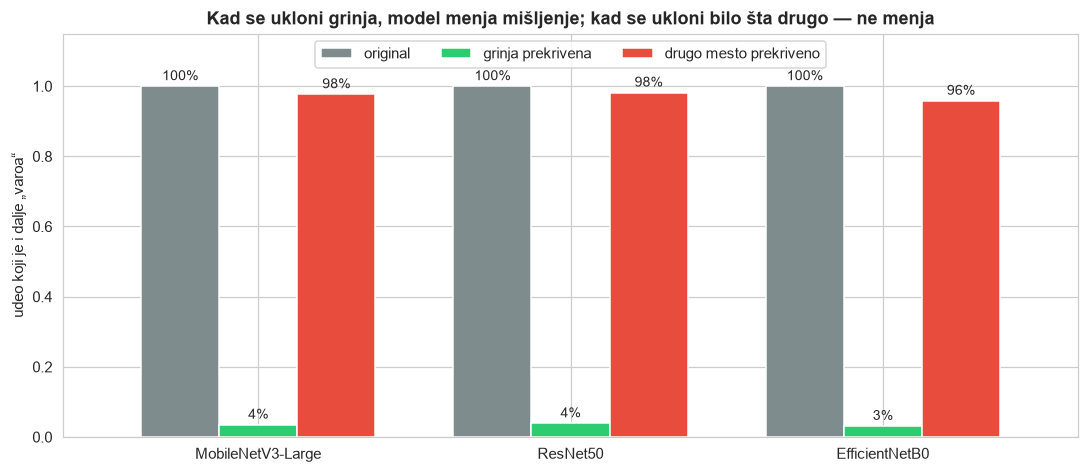

In [2]:
mk = pd.DataFrame({m: {"original": c["masking"]["prepoznato_kao_varoa_original"] / c["masking"]["prepoznato_kao_varoa_original"],
                       "grinja prekrivena": c["masking"]["ostalo_varoa_kad_se_grinja_prekrije"],
                       "drugo mesto prekriveno": c["masking"]["ostalo_varoa_kad_se_prekrije_drugo_mesto"]}
                   for m, c in checks.items()}).T
ax = mk.plot(kind="bar", figsize=(10, 4.4), rot=0, color=["#7f8c8d", "#2ecc71", "#e74c3c"], width=0.75)
oznaci_stubice(ax, "{:.0%}"); ax.set_ylim(0, 1.15); ax.set_xlabel("")
ax.set_ylabel("udeo koji je i dalje „varoa“"); ax.legend(loc="upper center", ncol=3)
ax.set_title("Kad se ukloni grinja, model menja mišljenje; kad se ukloni bilo šta drugo — ne menja")
plt.tight_layout(); sacuvaj("05a_brisanje_grinje"); plt.show()

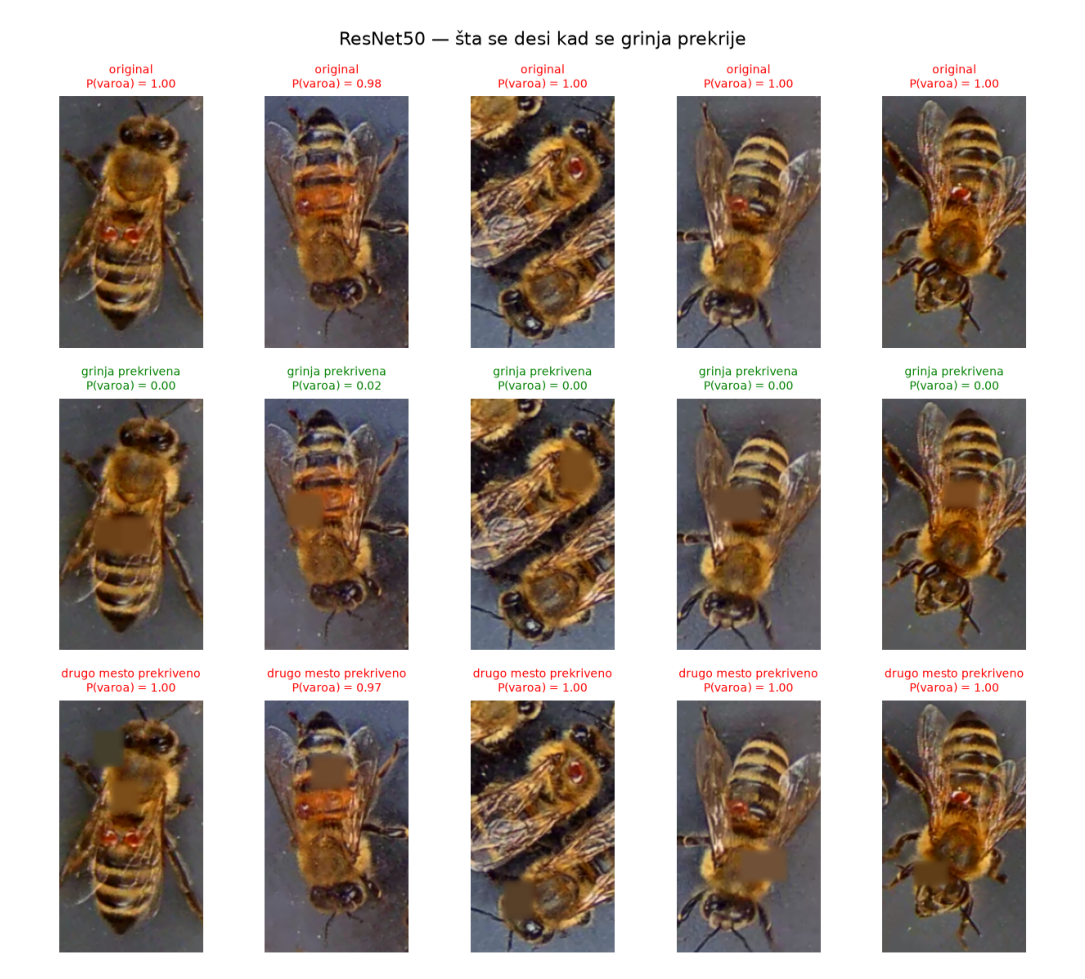

In [3]:
plt.figure(figsize=(10, 9)); plt.imshow(Image.open(RUNS / "varroa_resnet50" / "masking_examples.png")); plt.axis("off")
plt.tight_layout(); sacuvaj("05b_brisanje_primeri"); plt.show()

## 3. Provera 2 — samo pozadina

Modelu se daju samo uglovi slike (bez pčele). Kod BeeImage modela iz uglova je „prepoznata“ varoa u 74%
slučajeva. Novi modeli bi iz pozadine trebalo da kažu „varoa“ podjednako retko za zdrave i zaražene pčele.

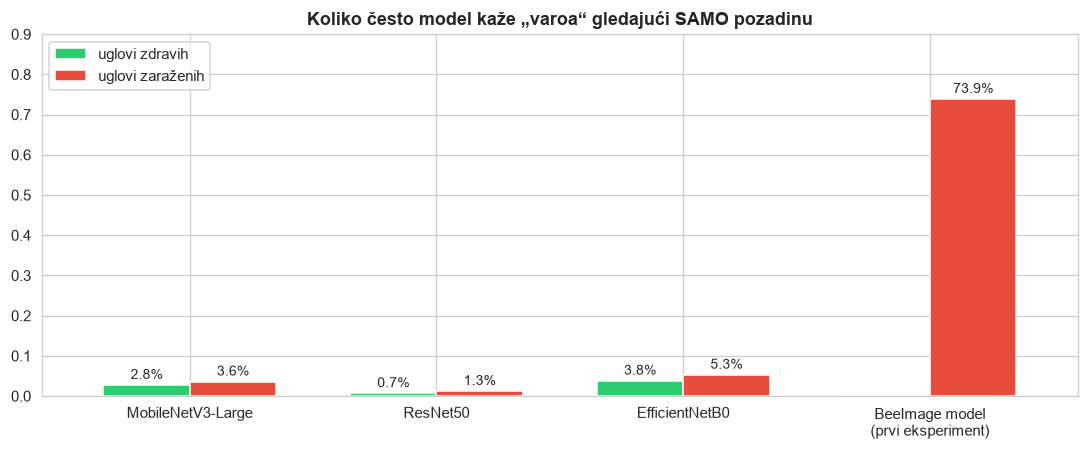

In [4]:
bg = pd.DataFrame({m: {"uglovi zdravih": c["background"]["udeo_varoa_uglovi_zdravih"],
                       "uglovi zaraženih": c["background"]["udeo_varoa_uglovi_zarazenih"]} for m, c in checks.items()}).T
bg.loc["BeeImage model\n(prvi eksperiment)"] = [np.nan, 0.739]
ax = bg.plot(kind="bar", figsize=(10, 4.2), rot=0, color=["#2ecc71", "#e74c3c"], width=0.7)
oznaci_stubice(ax, "{:.1%}"); ax.set_ylim(0, 0.9); ax.set_xlabel("")
ax.set_title("Koliko često model kaže „varoa“ gledajući SAMO pozadinu")
plt.tight_layout(); sacuvaj("05c_samo_pozadina"); plt.show()

## 4. Provera 3 — Grad-CAM (gde model gleda)

Grad-CAM boji delove slike koji su najviše doprineli odluci „varoa“ (crveno = najviše).
Gornji red: grinja iz `gt.csv`; donji red: mapa pažnje.

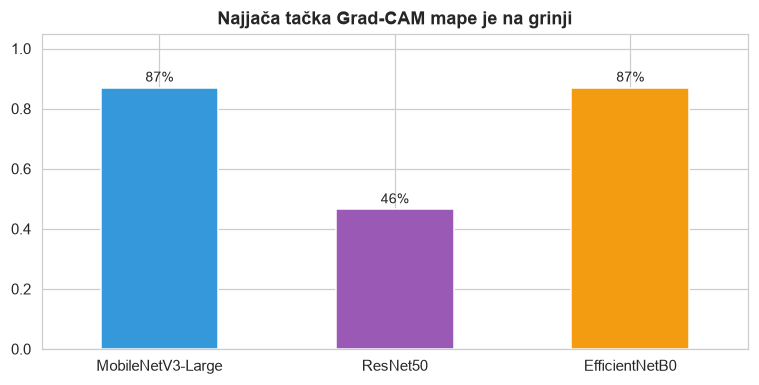

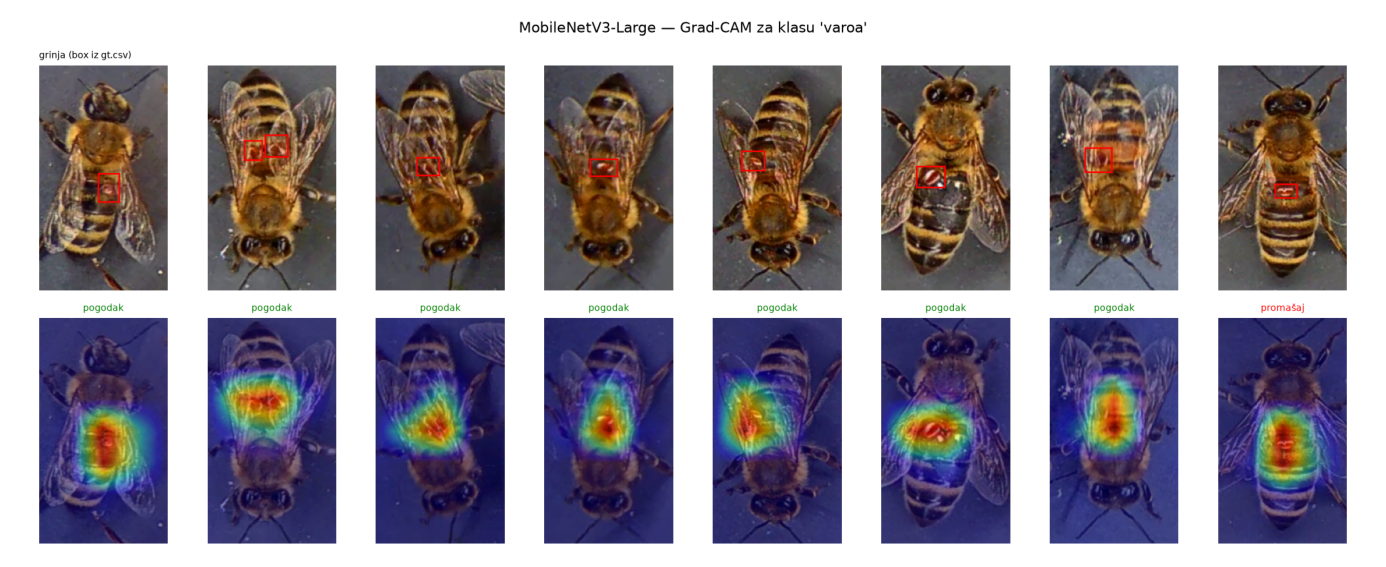

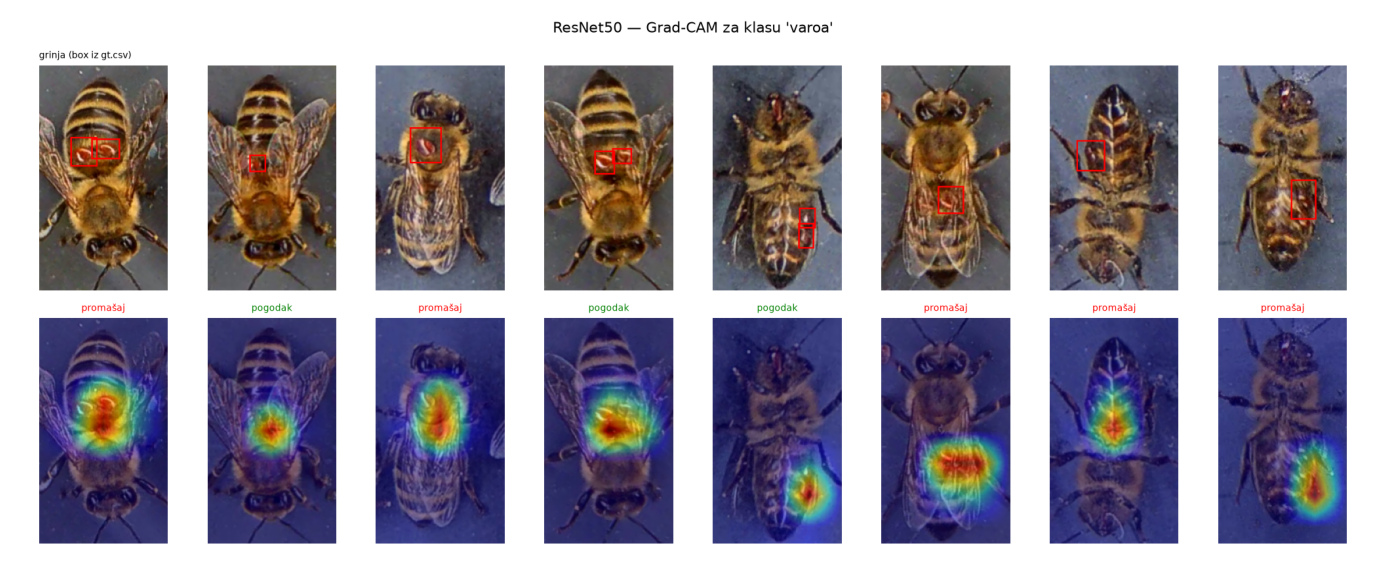

In [5]:
pg = pd.Series({m: c["gradcam_pointing"]["pogodak_u_grinju"] for m, c in checks.items()})
ax = pg.plot(kind="bar", figsize=(7, 3.6), rot=0, color=[BOJA_MODELA[m] for m in pg.index])
oznaci_stubice(ax, "{:.0%}"); ax.set_ylim(0, 1.05); ax.set_title("Najjača tačka Grad-CAM mape je na grinji")
plt.tight_layout(); sacuvaj("05d_gradcam_pogoci"); plt.show()
for m in ["MobileNetV3-Large", "ResNet50"]:
    plt.figure(figsize=(16, 6.6)); plt.imshow(Image.open(RUNS / RUN_ZA[m] / "gradcam.png")); plt.axis("off"); plt.show()

**Zaključak provera:** odluka sva tri modela **zavisi od grinje** (uklanjanje grinje ruši procenu sa ~87%
na 3–4%, uklanjanje drugog dela pčele ne). ResNet50 ima širu Grad-CAM mapu (obuhvata i okolni deo tela),
ali uzročni test — brisanje grinje — je presudan.

## 5. Test van skupa — BeeDataset (druga kamera, zelena podloga)

7.490 slika koje model nikad nije video, snimljenih potpuno drugom opremom.

In [6]:
from sklearn.metrics import roc_curve, roc_auc_score, recall_score, precision_score, accuracy_score
from src.predictions import predictions
bd = {m: predictions(RUN_ZA[m], "beedataset") for m in MODELI}
tab = pd.DataFrame({m: {"Tačnost": accuracy_score(p["true"], p["pred"]), "Odziv (varoa)": recall_score(p["true"], p["pred"]),
                        "Preciznost (varoa)": precision_score(p["true"], p["pred"]), "ROC AUC": roc_auc_score(p["true"], p["p_varoa"])}
                    for m, p in bd.items()}).T
tab.round(4)

,Tačnost,Odziv (varoa),Preciznost (varoa),ROC AUC
MobileNetV3-Large,0.8999,0.4755,0.8750,0.9488
ResNet50,0.8794,0.3049,0.9438,0.8694
EfficientNetB0,0.8650,0.2030,0.9923,0.9279


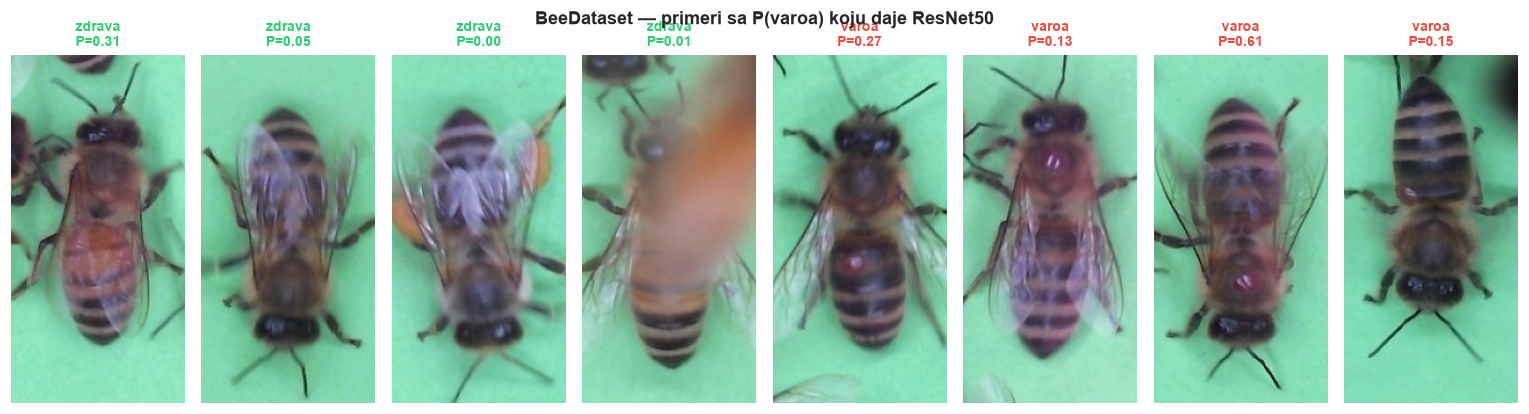

In [7]:
uz = bd["ResNet50"].groupby("true").sample(4, random_state=2)
fig, axes = plt.subplots(1, 8, figsize=(14, 3.8))
for ax, (_, r) in zip(axes, uz.iterrows()):
    ax.imshow(Image.open(r["path"])); ax.axis("off")
    ax.set_title(("varoa" if r["true"] else "zdrava") + f"\nP={r['p_varoa']:.2f}", fontsize=9,
                 color=BOJA_KLASE["varoa" if r["true"] else "zdrava"])
fig.suptitle("BeeDataset — primeri sa P(varoa) koju daje ResNet50", fontweight="bold")
plt.tight_layout(); sacuvaj("05e_beedataset_primeri"); plt.show()

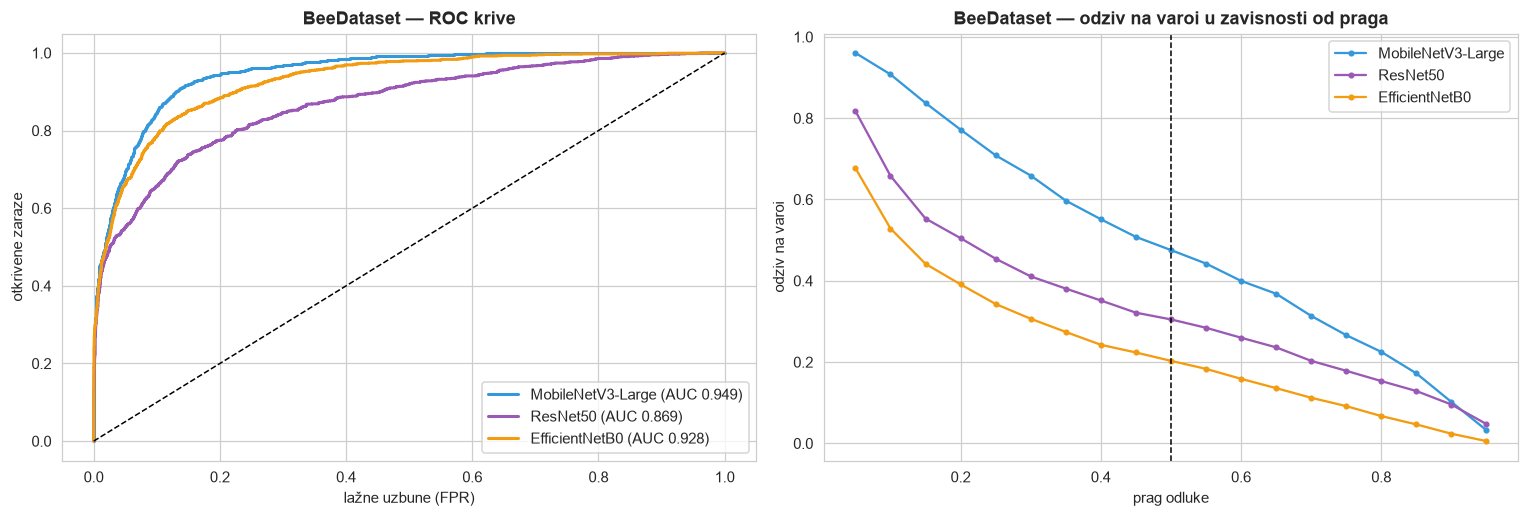

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for m in MODELI:
    p = bd[m]; fpr, tpr, _ = roc_curve(p["true"], p["p_varoa"])
    axes[0].plot(fpr, tpr, color=BOJA_MODELA[m], lw=2, label=f"{m} (AUC {roc_auc_score(p['true'], p['p_varoa']):.3f})")
    pragovi = np.linspace(0.05, 0.95, 19)
    axes[1].plot(pragovi, [((p["p_varoa"] >= t) & (p["true"] == 1)).sum() / p["true"].sum() for t in pragovi],
                 color=BOJA_MODELA[m], marker="o", ms=3, label=m)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("lažne uzbune (FPR)"); axes[0].set_ylabel("otkrivene zaraze")
axes[0].set_title("BeeDataset — ROC krive"); axes[0].legend(loc="lower right")
axes[1].axvline(0.5, color="k", ls="--", lw=1); axes[1].set_xlabel("prag odluke"); axes[1].set_ylabel("odziv na varoi")
axes[1].set_title("BeeDataset — odziv na varoi u zavisnosti od praga"); axes[1].legend()
plt.tight_layout(); sacuvaj("05f_beedataset_roc_prag"); plt.show()

**Zaključak:** modeli dobro **razdvajaju** zaražene od zdravih i na drugoj kameri (AUC 0,87–0,95), ali su
**previše oprezni**: na pragu 0,5 hvataju samo 20–48% zaraza. Spuštanjem praga odziv brzo raste — to je
jeftino poboljšanje bez ponovnog treninga (desni grafik).

## 6. Terenske fotografije (`data/field_photos/`)

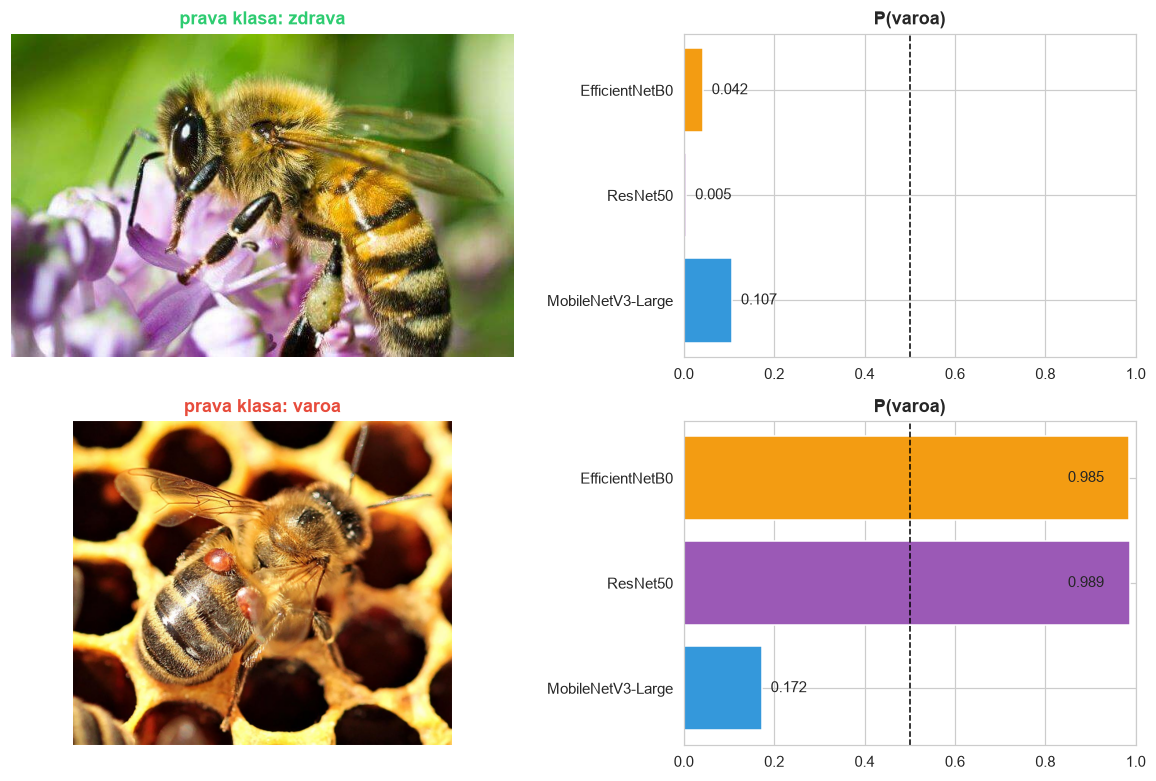

In [9]:
from src.field_test import field_photos
from src.field_test import _load_model, _p_varoa
fotke = field_photos()
pv = {}
for m in MODELI:
    _, model, tf = _load_model(RUN_ZA[m]); pv[m] = _p_varoa(model, tf, [f for f, _ in fotke])
fig, axes = plt.subplots(len(fotke), 2, figsize=(11, 3.6 * len(fotke)), gridspec_kw={"width_ratios": [1.3, 1]})
axes = np.atleast_2d(axes)
for i, (f, t) in enumerate(fotke):
    axes[i, 0].imshow(Image.open(f)); axes[i, 0].axis("off")
    axes[i, 0].set_title(f"prava klasa: {'varoa' if t else 'zdrava'}", color=BOJA_KLASE["varoa" if t else "zdrava"])
    vals = [pv[m][i] for m in MODELI]
    axes[i, 1].barh(MODELI, vals, color=[BOJA_MODELA[m] for m in MODELI]); axes[i, 1].set_xlim(0, 1)
    axes[i, 1].axvline(0.5, color="k", ls="--", lw=1)
    for j, v in enumerate(vals): axes[i, 1].text(min(v + 0.02, 0.85), j, f"{v:.3f}", va="center")
    axes[i, 1].set_title("P(varoa)")
plt.tight_layout(); sacuvaj("05g_terenske_fotografije"); plt.show()

## 7. Izbor modela — svi kriterijumi

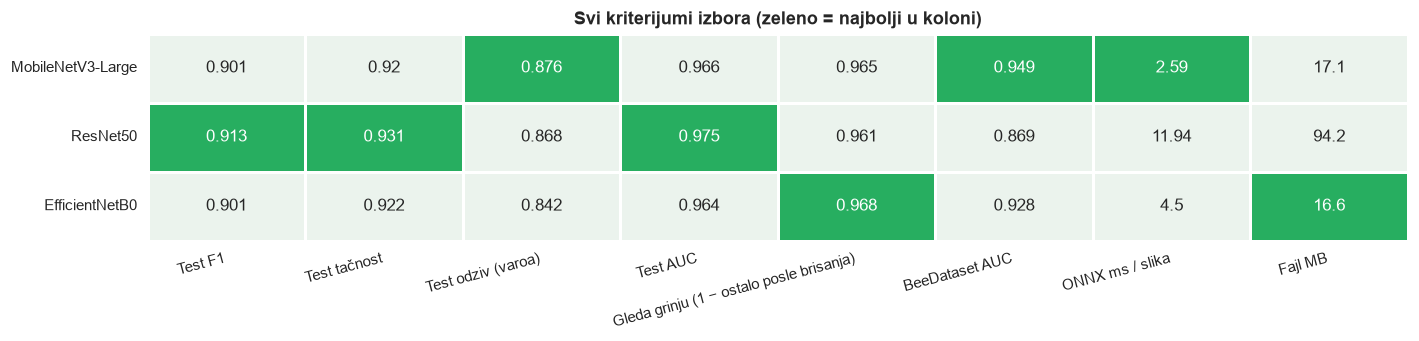

,onnx_batch1_ms,fajl_MB
model,,
MobileNetV3-Large,2.59,17.1
EfficientNetB0,4.50,16.6
ResNet50,11.94,94.2


In [10]:
from src.predictions import predictions as P
lat = pd.read_csv(ROOT / "models" / "latency_benchmark_varroa.csv").set_index("model")
kr = pd.DataFrame({m: {
    "Test F1": json.loads((RUNS / RUN_ZA[m] / "metrics.json").read_text())["macro_f1"],
    "Test tačnost": json.loads((RUNS / RUN_ZA[m] / "metrics.json").read_text())["accuracy"],
    "Test odziv (varoa)": json.loads((RUNS / RUN_ZA[m] / "metrics.json").read_text())["varroa_recall"],
    "Test AUC": json.loads((RUNS / RUN_ZA[m] / "metrics.json").read_text())["roc_auc"],
    "Gleda grinju (1 − ostalo posle brisanja)": 1 - checks[m]["masking"]["ostalo_varoa_kad_se_grinja_prekrije"],
    "BeeDataset AUC": roc_auc_score(bd[m]["true"], bd[m]["p_varoa"]),
    "ONNX ms / slika": lat.loc[m, "onnx_batch1_ms"],
    "Fajl MB": lat.loc[m, "fajl_MB"],
} for m in MODELI}).T
manje_je_bolje = ["ONNX ms / slika", "Fajl MB"]
najbolji = pd.DataFrame({k: (kr[k] == (kr[k].min() if k in manje_je_bolje else kr[k].max())).astype(float) for k in kr})
fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(najbolji, annot=kr.round(3).astype(str), fmt="", cmap=sns.light_palette("#27ae60", as_cmap=True),
            cbar=False, linewidths=0.8, linecolor="white", annot_kws={"size": 11}, ax=ax)
ax.set_title("Svi kriterijumi izbora (zeleno = najbolji u koloni)"); ax.set_ylabel("")
plt.xticks(rotation=15, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); sacuvaj("05h_svi_kriterijumi"); plt.show()
lat[["onnx_batch1_ms", "fajl_MB"]]

## 8. Odluka: **ResNet50**

- najbolji po **svim metrikama koje je profesorica navela** (tačnost, preciznost, odziv, F1) i po AUC
- najmanje lažnih uzbuna (111, naspram 156 kod MobileNetV3)
- prolazi uzročni test — odluka zavisi od grinje
- tačno prepoznaje terensku fotografiju na kojoj je BeeImage model pogrešio
- sporiji (12 ms) i veći (94 MB), ali za server je to nebitno

**Rezerve:** razlike su ~1 procentni poen (jedno seme); MobileNetV3 se bolje prenosi na BeeDataset i
4,6× je brži — bio bi bolji izbor za mobilni uređaj. Zamena modela u sistemu je zamena jednog fajla.

## 9. Provera kroz pravi servis (isti kod i ONNX fajl kao u aplikaciji)

In [11]:
from service.inference import BeeHealthModel
servis = BeeHealthModel(ROOT / "models" / "bee_health.onnx")
print("Model u servisu:", servis.arch, "| klase:", servis.classes, "\n")
for f, t in fotke:
    print(f"{'varoa ' if t else 'zdrava'}  {Path(f).name:38s} ->", servis.predict(Path(f).read_bytes()))
print("\nProvera na celom test skupu:", json.loads((ROOT / "models" / "verification.json").read_text()))

Model u servisu: ResNet50 | klase: ['zdrava', 'varoa'] 

zdrava  pcela_na_cvetu.jpg                     -> {'label': 'zdrava', 'confidence': 0.9948, 'all_probs': {'zdrava': 0.9948, 'varoa': 0.0052}, 'model_version': 'bee_health'}
varoa   makro_pcela_na_sacu_2_grinje.jpg       -> {'label': 'varoa', 'confidence': 0.9886, 'all_probs': {'zdrava': 0.0114, 'varoa': 0.9886}, 'model_version': 'bee_health'}

Provera na celom test skupu: {'model': 'ResNet50', 'source_run': 'varroa_resnet50', 'test_slika': 3408, 'najveca_razlika_verovatnoce': 5.1e-05, 'razlicitih_predikcija': 0, 'accuracy_servisa': 0.931, 'ok': True}
